In [1]:
import jax.numpy as jnp
from granad.materials import Material
import numpy as np
from granad import Rectangle

from collections import defaultdict
import matplotlib.pyplot as plt

In [2]:
def show_energies(orbs, display = None, label = None, e_max = None, e_min = None, figsize=None, circle_scale=20):
    """
    Depicts the energy and occupation landscape of a stack, with energies plotted on the y-axis and eigenstates ordered by size on the x-axis.

    Parameters:
        `orbs`: An object containing the orbital data, including energies, electron counts, and initial density matrix.
        `display` (jnp.Array, optional): Array to annotate the energy states.
            - If `None`, electronic occupation is used.
        `label` (jnp.Array, optional): Label for the colorbar.
            - If `None`, "initial state occupation" is used.
        `e_max` (float, optional): The upper limit of the energy range to display on the y-axis. 
            - If `None`, the maximum energy is used by default.
            - This parameter allows you to zoom into a specific range of energies for a more focused view.
        `e_min` (float, optional): The lower limit of the energy range to display on the y-axis.
            - If `None`, the minimum energy is used by default.
            - This parameter allows you to filter out higher-energy states and focus on the lower-energy range.

    Notes:
        The scatter plot displays the eigenstate number on the x-axis and the corresponding energy (in eV) on the y-axis.
        The color of each point represents the initial state occupation, calculated as the product of the electron count and the initial density matrix diagonal element for each state.
        A color bar is added to indicate the magnitude of the initial state occupation for each eigenstate.
    """
    from matplotlib.ticker import MaxNLocator
    e_max = (e_max or orbs.energies.max()) 
    e_min = (e_min or orbs.energies.min())
    widening = (e_max - e_min) * 0.01 # 1% larger in each direction
    e_max += widening
    e_min -= widening
    energies_filtered_idxs = jnp.argwhere( jnp.logical_and(orbs.energies <= e_max, orbs.energies >= e_min))
    state_numbers = energies_filtered_idxs[:, 0]
    energies_filtered = orbs.energies[energies_filtered_idxs]

    if display is None:
        display = jnp.diag(orbs.electrons * orbs.initial_density_matrix_e)
    label = label or "initial state occupation"
    
    colors =  display[energies_filtered_idxs]

    fig, ax = plt.subplots(1, 1, figsize=figsize)
    plt.colorbar(
        ax.scatter(
            state_numbers,
            energies_filtered,
            c=colors,
            s=circle_scale
        ),
        label=label,
    )
    ax.set_xlabel("eigenstate number")
    ax.set_ylabel("energy (eV)")
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(e_min, e_max)    



In [3]:
def show_2d(orbs, show_tags=None, show_index=False, display = None, 
                scale = False, cmap = None, circle_scale : float = 1e3, 
                title = None, mode = None, indicate_atoms = False, grid = False,
                clims = None):
    """
    Generates a 2D scatter plot representing the positions of orbitals in the xy-plane, with optional filtering, coloring, and sizing.

    Parameters:
        `orbs` (list): List of orbital objects, each containing attributes such as 'tag' (for labeling) and 'position' (xy-coordinates).
        `show_tags` (list of str, optional): Filters the orbitals to display based on their tags. Only orbitals with matching tags will be shown. If `None`, all orbitals are displayed.
        `show_index` (bool, optional): If `True`, displays the index of each orbital next to its corresponding point on the plot.
        `display` (array-like, optional): Data used to color and scale the points (e.g., eigenvector amplitudes). Each value corresponds to an orbital.
        `scale` (bool, optional): If `True`, the values in `display` are normalized and their absolute values are used.
        `cmap` (optional): Colormap used for the scatter plot when `display` is provided. If `None`, a default colormap (`bwr`) is used.
        `circle_scale` (float, optional): A scaling factor for the size of the scatter plot points. Larger values result in larger circles. Default is 1000.
        `title` (str, optional): Custom title for the plot. If `None`, the default title "Orbital positions in the xy-plane" is used.
        `mode` (str, optional): Determines the plotting style for orbitals when `display` is provided.
            - `'two-signed'`: Displays orbitals with a diverging colormap centered at zero, highlighting both positive and negative values symmetrically. 
                              The colormap is scaled such that its limits are set by the maximum absolute value in the `display` array.
            - `'one-signed'`: Displays orbitals with a sequential colormap, highlighting only positive values. Negative values are ignored in this mode.
            - `None`: Defaults to a general plotting mode that uses the normalized values from `display` for coloring and sizing.
        `indicate_atoms` (bool, optional): Show atoms as black dots if `display` is given, defaults to False.
        `grid`(bool, optional): Shows grid, `False` by default.

    
    Notes:
        If `display` is provided, the points are colored and sized according to the values in the `display` array, and a color bar is added to the plot.
        If `show_index` is `True`, the indices of the orbitals are annotated next to their corresponding points.
        The plot is automatically adjusted to ensure equal scaling of the axes, and grid lines are displayed.    
    """

    # decider whether to take abs val and normalize 
    def scale_vals( vals ):
        return jnp.abs(vals) / jnp.abs(vals).max() if scale else vals

    # Determine which tags to display
    if show_tags is None:
        show_tags = {orb.tag for orb in orbs}
    else:
        show_tags = set(show_tags)

    # Prepare data structures for plotting
    tags_to_pos, tags_to_idxs = defaultdict(list), defaultdict(list)
    for orb in orbs:
        if orb.tag in show_tags:
            tags_to_pos[orb.tag].append(orb.position)
            tags_to_idxs[orb.tag].append(orbs.index(orb))

    # Create plot
    fig, ax = plt.subplots(figsize=(10,8))
    if display is not None:        
        cmap = plt.cm.bwr if cmap is None else cmap
        if mode == 'two-signed':
            display = display.real
            dmax = jnp.max(jnp.abs(display))            
            scatter = ax.scatter([orb.position[0] for orb in orbs], [orb.position[1] for orb in orbs], c = display, edgecolor=None, cmap=cmap, s = circle_scale / 10 )
            if c_lims is None:
                scatter.set_clim(-dmax, dmax)
            else:
                scatter.set_clim(clims)
        elif mode == 'one-signed':
            cmap = plt.cm.Reds
            display = display.real
            dmax = display[jnp.argmax(jnp.abs(display))]
            scatter = ax.scatter([orb.position[0] for orb in orbs], [orb.position[1] for orb in orbs], c = display, edgecolor=None, cmap=cmap, s = circle_scale / 10 )
            if(dmax<0):
                scatter.set_clim(dmax, 0)
            else:
                scatter.set_clim(0, dmax)
        else:
            colors = scale_vals(display)            
            scatter = ax.scatter([orb.position[0] for orb in orbs], [orb.position[1] for orb in orbs], c=colors, edgecolor=None, cmap=cmap, s = circle_scale*jnp.abs(display) )
            if clims is not None:
                # display = display.real
                # dmax = jnp.max(jnp.abs(display))
                scatter.set_clim(clims)
        if indicate_atoms == True:
            ax.scatter([orb.position[0] for orb in orbs], [orb.position[1] for orb in orbs], color='black', s=10, marker='o')            
        cbar = fig.colorbar(scatter, ax=ax)
        
    else:
        # Color by tags if no show_state is given
        unique_tags = list(set(orb.tag for orb in orbs))
        color_map = {tag: plt.cm.get_cmap('tab10')(i / len(unique_tags)) for i, tag in enumerate(unique_tags)}
        for tag, positions in tags_to_pos.items():
            positions = jnp.array(positions)
            ax.scatter(positions[:, 0], positions[:, 1], label=tag, color=color_map[tag], edgecolor='white', alpha=0.7)
        plt.legend(title='Orbital Tags')

    # Optionally annotate points with their indexes
    if show_index:
        for orb in [orb for orb in orbs if orb.tag in show_tags]:
            pos = orb.position
            idx = orbs.index(orb)
            ax.annotate(str(idx), (pos[0], pos[1]), textcoords="offset points", xytext=(0,10), ha='center')

    # Finalize plot settings
    if title is not None:
        plt.title(title)
    plt.xlabel('X')
    plt.ylabel('Y')
    ax.grid(grid)
    ax.axis('equal')


In [4]:
### SETUP GOLDENE PROPERTIES - TWO OPTIONS

# Lattice constant and vectors are the same in both approaches
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

# OPTION 2 - basic goldene definition (no overlap matrix)
# hoppings here taken from DFTB file and inserted manually, 
# you can choose how many you want to include or modify freely
# au_s_hoppings = [-0.21077006, -0.13214205, -0.13783432, -0.14574128, -0.13393609, 
#                  -0.10941234, -0.10042629, -0.07758373, -0.05948577, -0.04918632, -0.03387146, 
#                  -0.02792838, -0.02547764, -0.01914361, -0.01170436, -0.01071128, -0.0087787, 
#                  -0.00603112, -0.00375732, -0.00339428]

au_s_hoppings = [-0.21077006, -0.13214205]   

goldene_simple = (Material("Au")
        .lattice_constant(lattice_constant)  # Approximate lattice constant of hBN
        .lattice_basis(lattice_basis)
        .add_orbital_species("s_gold", atom='Au')
        .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
        .add_interaction(
            "hamiltonian",
            participants=("s_gold", "s_gold"),
            parameters=au_s_hoppings,  
        )   )

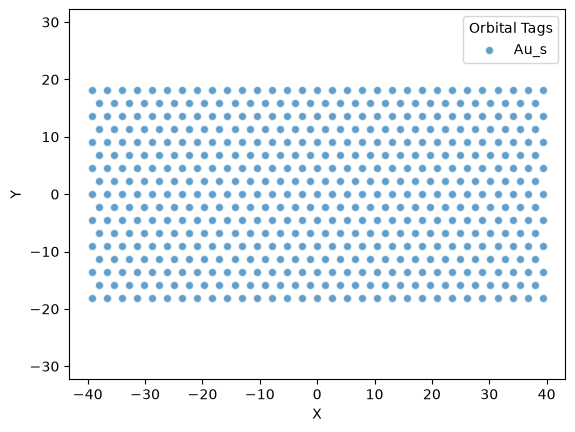

In [5]:
flake_sd = goldene_simple.cut_flake( Rectangle(40,40) )
flake_sd.show_2d(show_index=False)

[-0.21077006 -0.13214205  0.        ]
[-0.1403019  -0.13880101 -0.13833146 -0.13702401 -0.13476803 -0.13441247
 -0.13405244 -0.13157891 -0.12866549 -0.12747978 -0.12591928 -0.12462818
 -0.12105849 -0.12013966 -0.11699726 -0.11494732 -0.1143493  -0.1126921
 -0.1123313  -0.11146714 -0.10963291 -0.10727755 -0.10660743 -0.10500182
 -0.1045954  -0.10407962 -0.09514264 -0.09298168 -0.0928622  -0.08880246
 -0.08840572 -0.08774335 -0.0861874  -0.08557589 -0.08486341 -0.08295243
 -0.08077296 -0.07838787 -0.07487557 -0.0729052 ]


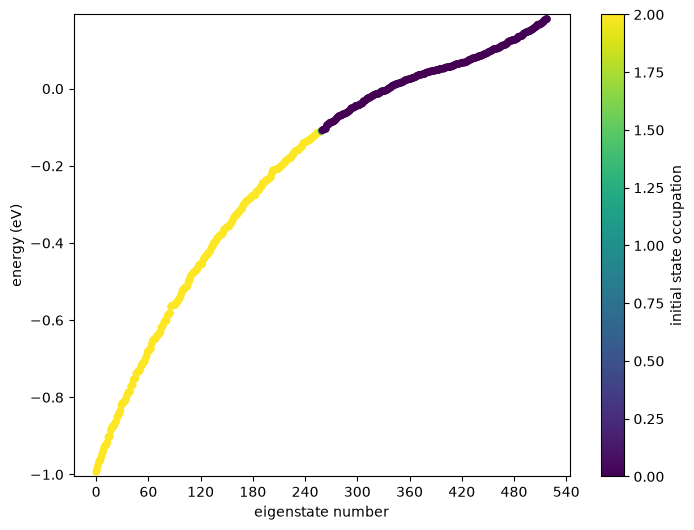

In [6]:
print(np.unique(flake_sd.hamiltonian.real))
print(flake_sd.energies[flake_sd.homo-20 : flake_sd.homo+20])
show_energies(flake_sd, figsize=(8,6))